# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [ ]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")




## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [ ]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.
from IPython.display import display
import subprocess, sys

file_id = "1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd"
csv_path = "/content/house_value_insights.csv"

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

downloaded = gdown.download(id=file_id, output=csv_path, quiet=False)
if not downloaded or not os.path.exists(csv_path):
    raise RuntimeError("Не вдалося завантажити CSV. Завантажте файл вручну через files.upload().")

df = pd.read_csv(csv_path)
print(f"Дані завантажено: {df.shape[0]} рядків, {df.shape[1]} стовпців")
display(df.head())




Downloading...
From: https://drive.google.com/uc?id=1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd
To: /content/house_value_insights.csv
100%|██████████| 54.8k/54.8k [00:00<00:00, 8.60MB/s]

Дані завантажено: 1000 рядків, 8 стовпців


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.600,0,5,"262,382.852"
1,4272,3,3,2016,4.753,1,6,"985,260.854"
2,3592,1,2,2016,3.635,0,9,"777,977.390"
3,966,1,2,1977,2.731,1,8,"229,698.919"
4,4926,2,1,1993,4.699,0,8,"1,041,740.859"


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [ ]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.

!pip -q install kagglehub
import kagglehub
kaggle_dir = kagglehub.dataset_download("prokshitha/home-value-insights")
csv_files = glob.glob(os.path.join(kaggle_dir, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError("У завантаженому датасеті не знайдено CSV-файлів.")
df = pd.read_csv(csv_files[0])
print(f"Дані завантажено: {df.shape[0]} рядків, {df.shape[1]} стовпців")
display(df.head())



Using Colab cache for faster access to the 'home-value-insights' dataset.
Дані завантажено: 1000 рядків, 8 стовпців


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.600,0,5,"262,382.852"
1,4272,3,3,2016,4.753,1,6,"985,260.854"
2,3592,1,2,2016,3.635,0,9,"777,977.390"
3,966,1,2,1977,2.731,1,8,"229,698.919"
4,4926,2,1,1993,4.699,0,8,"1,041,740.859"


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [ ]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.
display(df.head())
print("\nРозмір DataFrame (рядки, стовпці):", df.shape)
print("\nНазви стовпців:")
print(df.columns.tolist())
print("\nТипи даних і кількість непорожніх значень:")
df.info()





,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.600,0,5,"262,382.852"
1,4272,3,3,2016,4.753,1,6,"985,260.854"
2,3592,1,2,2016,3.635,0,9,"777,977.390"
3,966,1,2,1977,2.731,1,8,"229,698.919"
4,4926,2,1,1993,4.699,0,8,"1,041,740.859"



Розмір DataFrame (рядки, стовпці): (1000, 8)

Назви стовпців:
['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality', 'House_Price']

Типи даних і кількість непорожніх значень:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [ ]:
# Ваш код:
# Порахуйте кількість дублікатів.

print("Кількість дублікатів:", df.duplicated().sum())



Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [ ]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.

display(df.isna().sum().to_frame("Кількість пропусків"))



,Кількість пропусків
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [ ]:
# Ваш код:
# Отримайте описову статистику датасету.

display(df.describe().T)



,count,mean,std,min,25%,50%,75%,max
Square_Footage,"1,000.000","2,815.422","1,255.515",503.000,"1,749.500","2,862.500","3,849.500","4,999.000"
Num_Bedrooms,"1,000.000",2.990,1.428,1.000,2.000,3.000,4.000,5.000
Num_Bathrooms,"1,000.000",1.973,0.820,1.000,1.000,2.000,3.000,3.000
Year_Built,"1,000.000","1,986.550",20.633,"1,950.000","1,969.000","1,986.000","2,004.250","2,022.000"
Lot_Size,"1,000.000",2.778,1.298,0.506,1.666,2.810,3.923,4.989
Garage_Size,"1,000.000",1.022,0.815,0.000,0.000,1.000,2.000,2.000
Neighborhood_Quality,"1,000.000",5.615,2.887,1.000,3.000,6.000,8.000,10.000
House_Price,"1,000.000","618,861.019","253,568.058","111,626.853","401,648.229","628,267.291","827,141.278","1,108,236.836"


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [ ]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.

if "Neighborhood_Quality" not in df.columns:
    raise KeyError("У датасеті немає стовпця Neighborhood_Quality. Перевірте df.columns.")
display(df["Neighborhood_Quality"].value_counts(dropna=False).sort_index().to_frame("Кількість"))



,Кількість
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

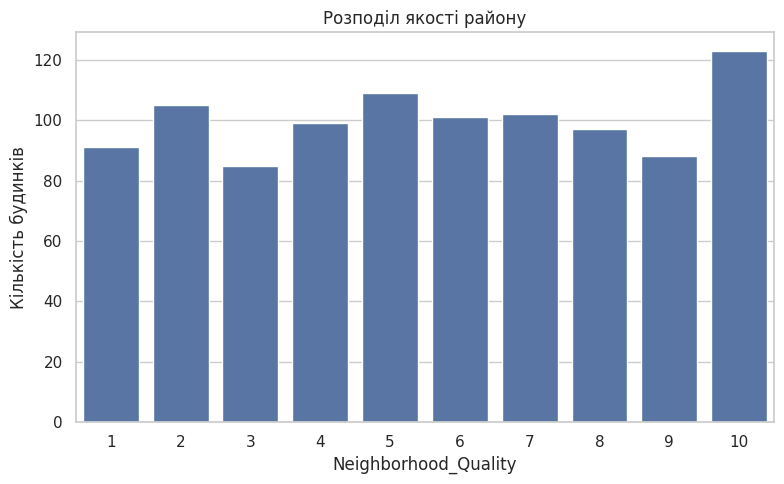

In [ ]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Neighborhood_Quality", order=sorted(df["Neighborhood_Quality"].dropna().unique()))
plt.title("Розподіл якості району")
plt.xlabel("Neighborhood_Quality")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()




### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [ ]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.

if "Num_Bathrooms" not in df.columns:
    raise KeyError("У датасеті немає стовпця Num_Bathrooms. Перевірте df.columns.")
display(df["Num_Bathrooms"].value_counts(dropna=False).sort_index().to_frame("Кількість"))



,Кількість
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

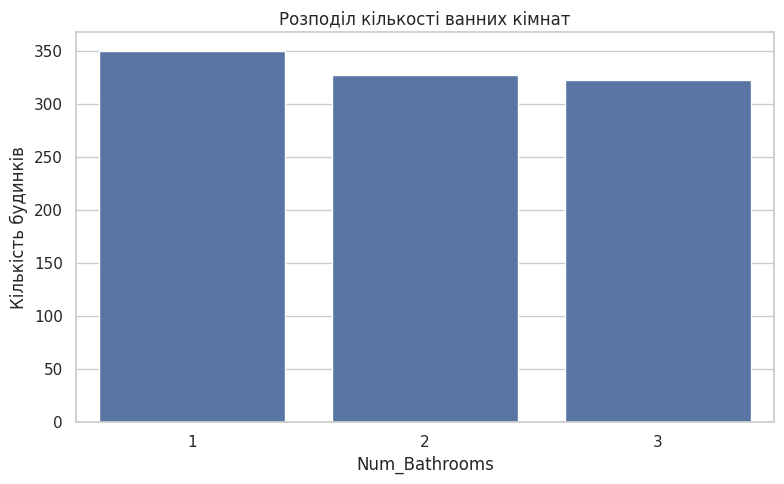

In [ ]:
# Ваш код:
# Побудуйте відповідну діаграму.
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Num_Bathrooms", order=sorted(df["Num_Bathrooms"].dropna().unique()))
plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Num_Bathrooms")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()




### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

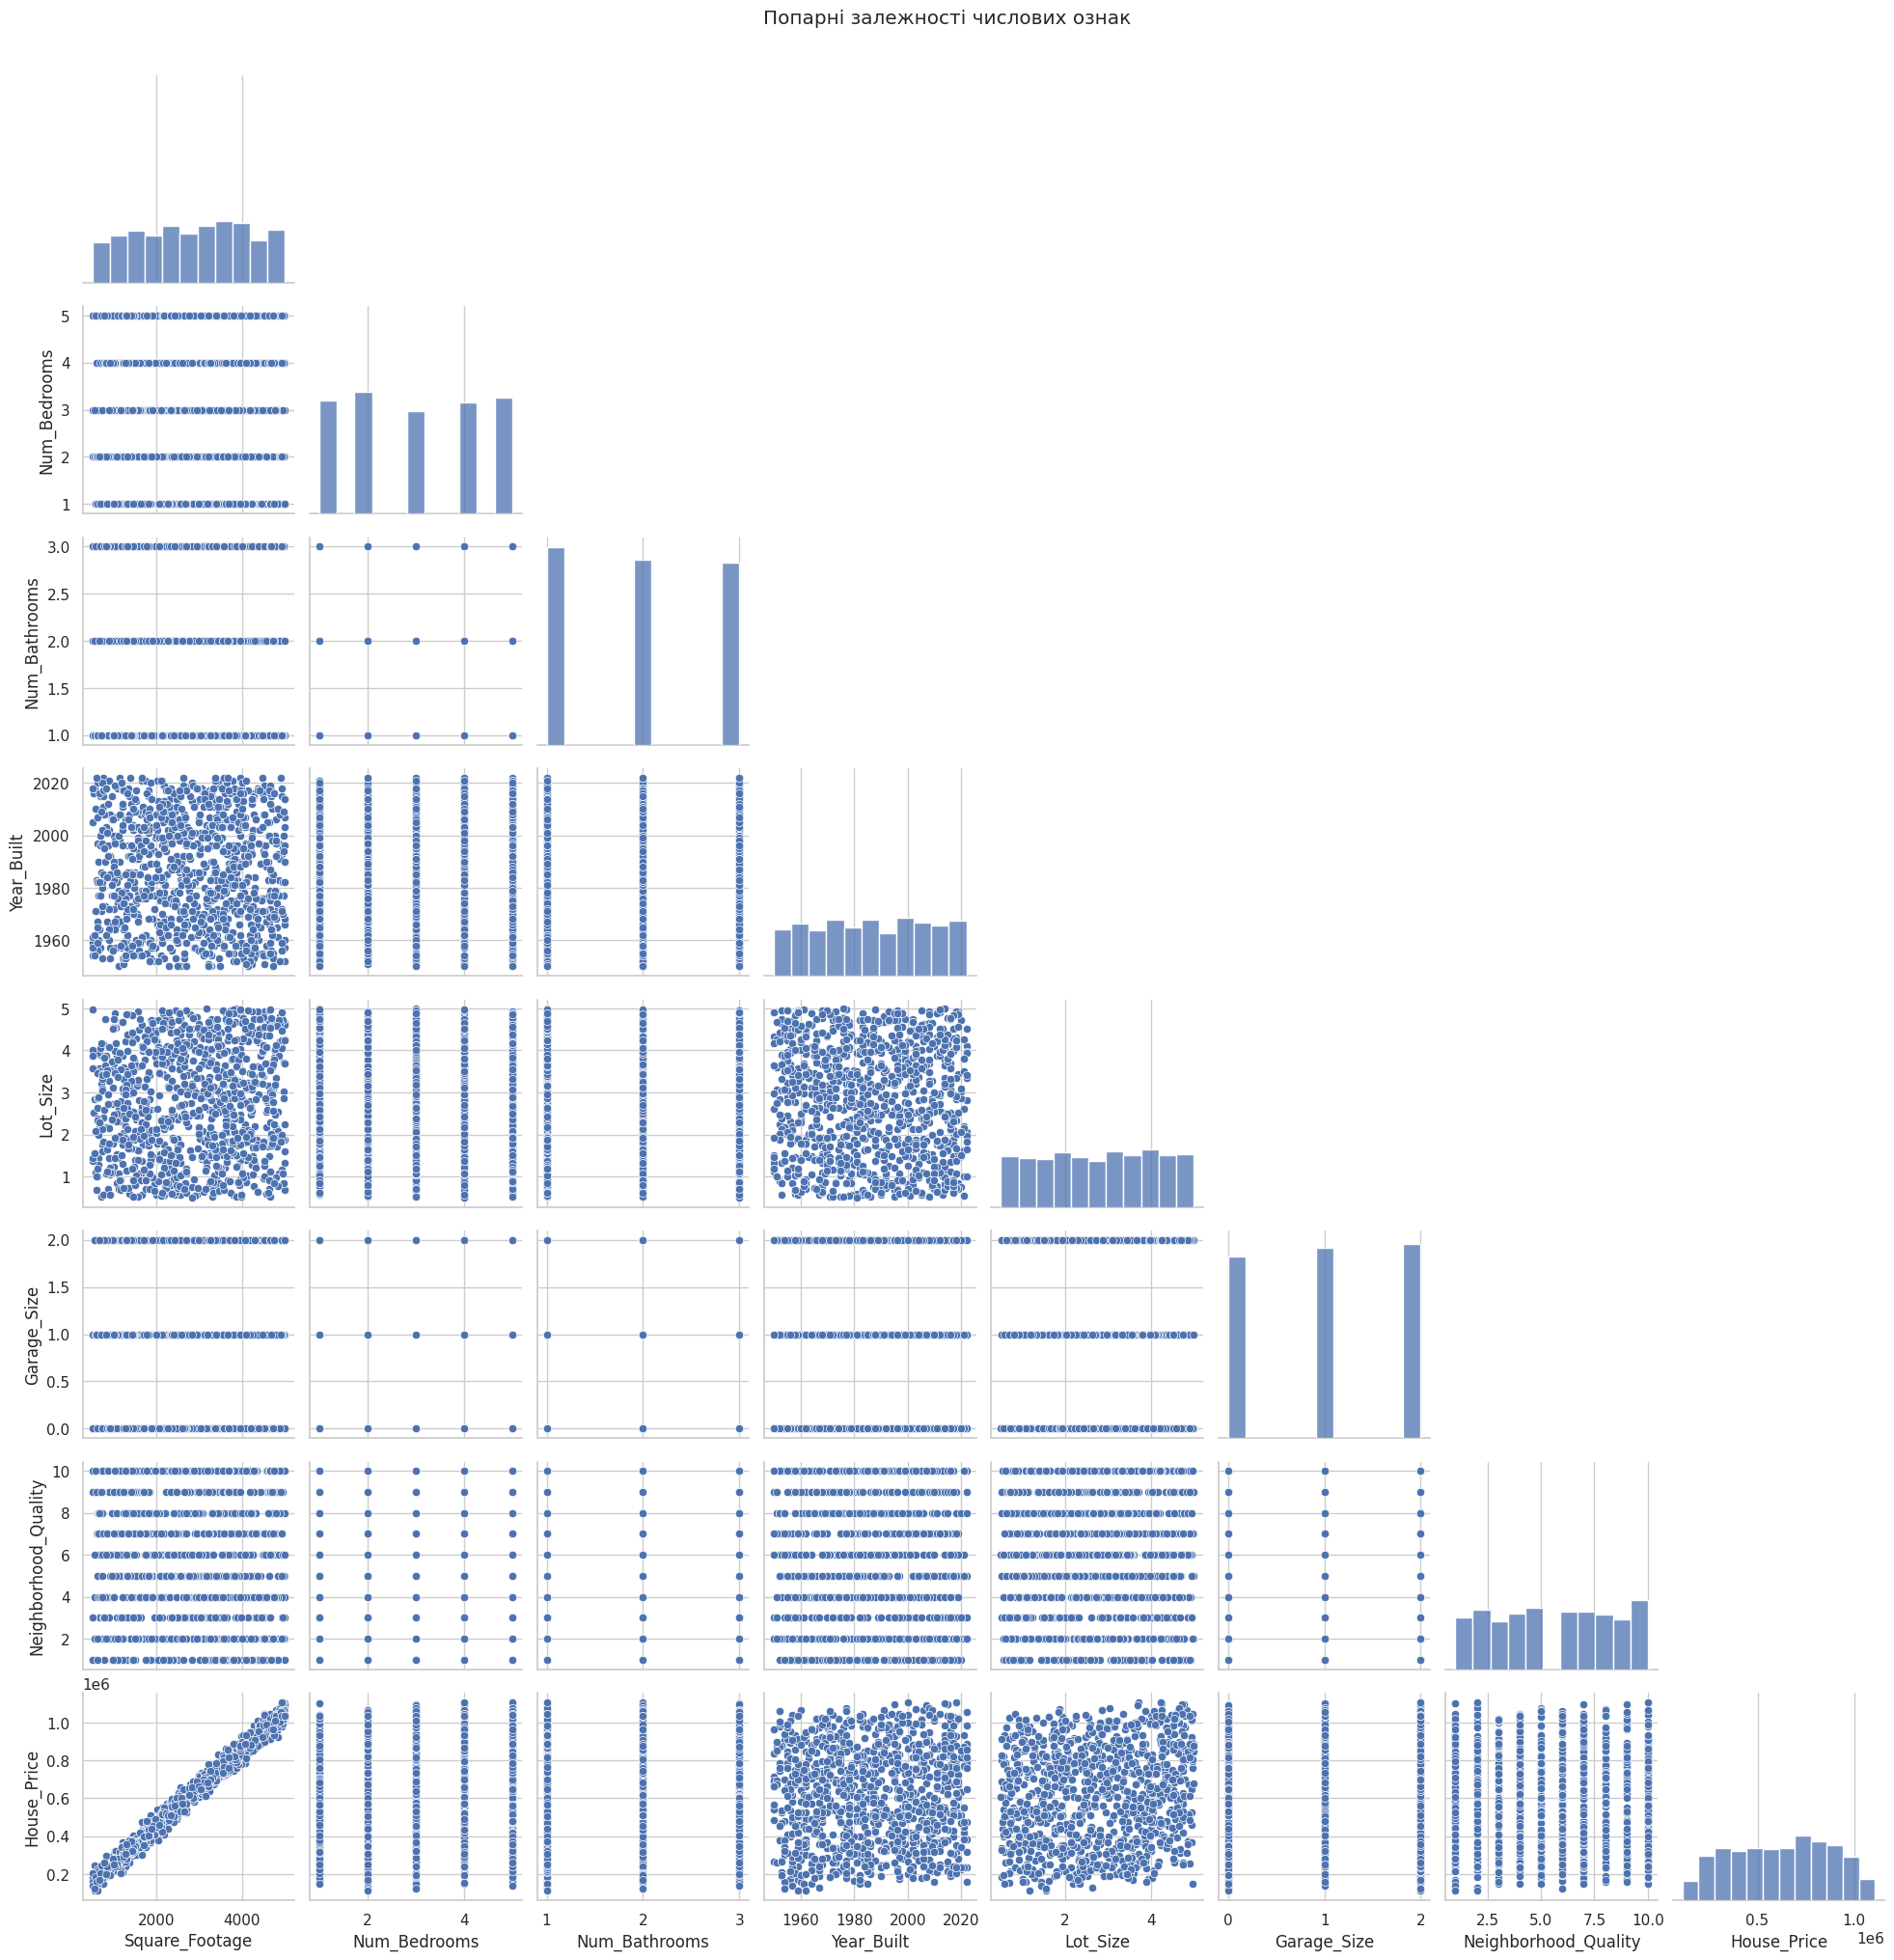

In [ ]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if len(numeric_cols) > 1:
    # Обмежуємо кількість рядків, щоб pairplot працював швидше на великих даних
    pair_df = df[numeric_cols].dropna()
    if len(pair_df) > 1000:
        pair_df = pair_df.sample(1000, random_state=42)
    sns.pairplot(pair_df, corner=True, diag_kind="hist")
    plt.suptitle("Попарні залежності числових ознак", y=1.02)
    plt.show()
else:
    print("Для pairplot недостатньо числових ознак.")




## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

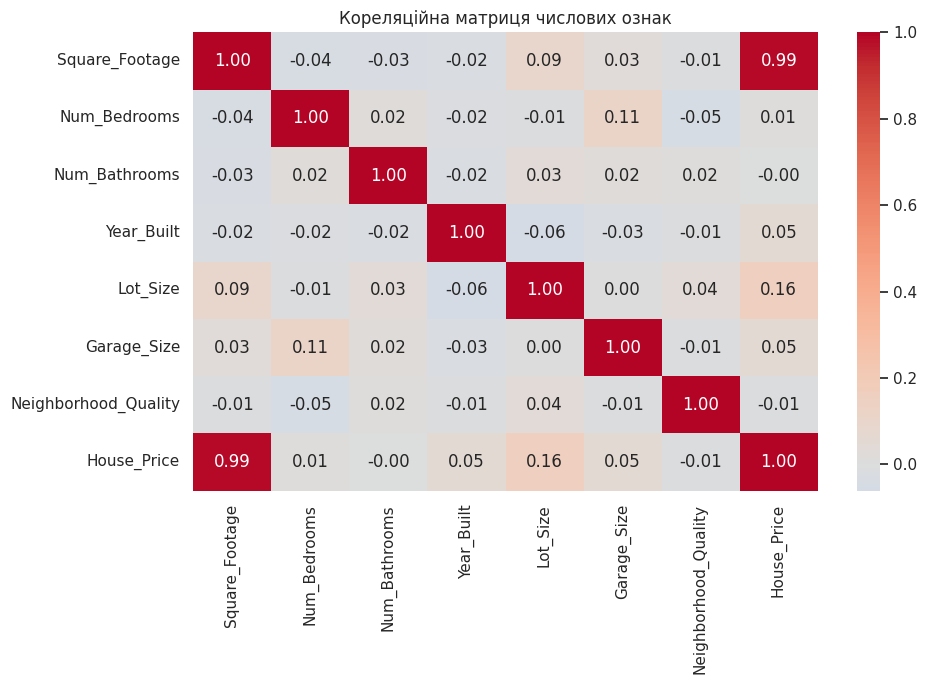

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
Square_Footage,1.000,-0.044,-0.032,-0.022,0.089,0.031,-0.008,0.991
Num_Bedrooms,-0.044,1.000,0.023,-0.016,-0.009,0.114,-0.049,0.015
Num_Bathrooms,-0.032,0.023,1.000,-0.021,0.035,0.025,0.018,-0.002
Year_Built,-0.022,-0.016,-0.021,1.000,-0.061,-0.025,-0.010,0.052
Lot_Size,0.089,-0.009,0.035,-0.061,1.000,0.002,0.038,0.160
Garage_Size,0.031,0.114,0.025,-0.025,0.002,1.000,-0.011,0.052
Neighborhood_Quality,-0.008,-0.049,0.018,-0.010,0.038,-0.011,1.000,-0.008
House_Price,0.991,0.015,-0.002,0.052,0.160,0.052,-0.008,1.000


In [ ]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.

numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False)
plt.title("Кореляційна матриця числових ознак")
plt.tight_layout()
plt.show()
display(corr)



### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [ ]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.
if "House_Price" not in df.columns:
    raise KeyError("У датасеті немає цільового стовпця House_Price.")
price_corr = df.select_dtypes(include=np.number).corr()["House_Price"].drop("House_Price").sort_values(ascending=False)
display(price_corr.to_frame("Кореляція з House_Price"))




,Кореляція з House_Price
Square_Footage,0.991
Lot_Size,0.160
Garage_Size,0.052
Year_Built,0.052
Num_Bedrooms,0.015
Num_Bathrooms,-0.002
Neighborhood_Quality,-0.008


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [ ]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error




### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [ ]:
# Ваш код:
# Створіть `X` та `y`.
if "House_Price" not in df.columns:
    raise KeyError("Не знайдено стовпець House_Price.")
model_df = df.copy()
model_df = model_df.drop_duplicates()
model_df["House_Price"] = pd.to_numeric(model_df["House_Price"], errors="coerce")
model_df = model_df.dropna(subset=["House_Price"])

y = model_df["House_Price"]
X = model_df.drop(columns=["House_Price"])
# Для цього завдання використовуємо числові ознаки, описані в умові
X = X.select_dtypes(include=np.number)
# Вилучаємо рядки, де цільова змінна відсутня; пропуски в X імпутуються в Pipeline
print("Кількість об'єктів:", len(X))
print("Використані ознаки:", X.columns.tolist())
print("Розмір X:", X.shape, "| Розмір y:", y.shape)




Кількість об'єктів: 1000
Використані ознаки: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality']
Розмір X: (1000, 7) | Розмір y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [ ]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Навчальна вибірка:", X_train.shape, y_train.shape)
print("Тестова вибірка:", X_test.shape, y_test.shape)




Навчальна вибірка: (800, 7) (800,)
Тестова вибірка: (200, 7) (200,)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [ ]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=20000))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}
print("Створено моделей:", len(models))
print(*models.keys(), sep="\n")




Створено моделей: 5
Linear Regression
Ridge
Lasso
Random Forest
Gradient Boosting


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [ ]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.
results = []
predictions = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    trained_models[name] = model
    predictions[name] = y_pred
    results.append({
        "Модель": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("R²", ascending=False).reset_index(drop=True)
display(results_df)




,Модель,R²,MAE,MSE
0,Linear Regression,0.998,"8,174.584","101,434,798.506"
1,Lasso,0.998,"8,174.748","101,436,558.180"
2,Ridge,0.998,"8,241.587","102,480,990.009"
3,Gradient Boosting,0.997,"12,305.218","224,965,597.845"
4,Random Forest,0.994,"16,114.290","394,131,747.446"


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

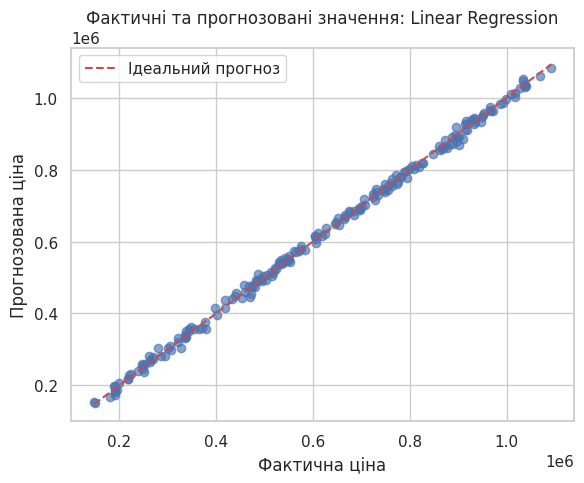

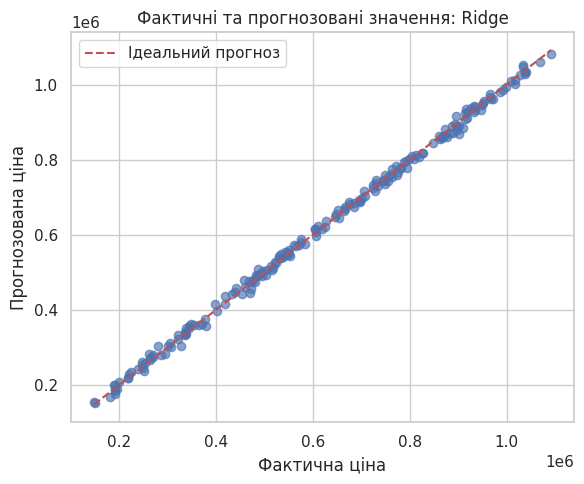

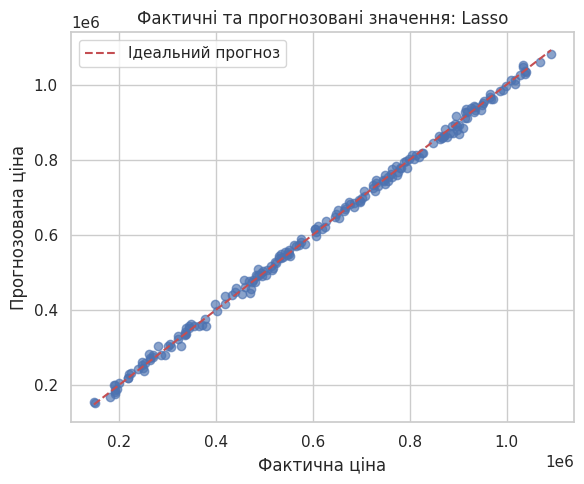

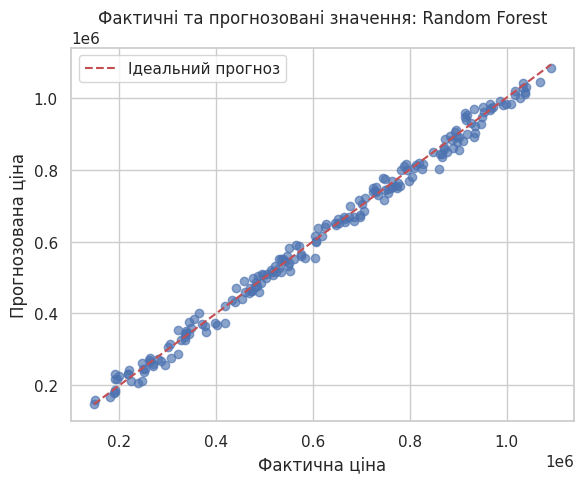

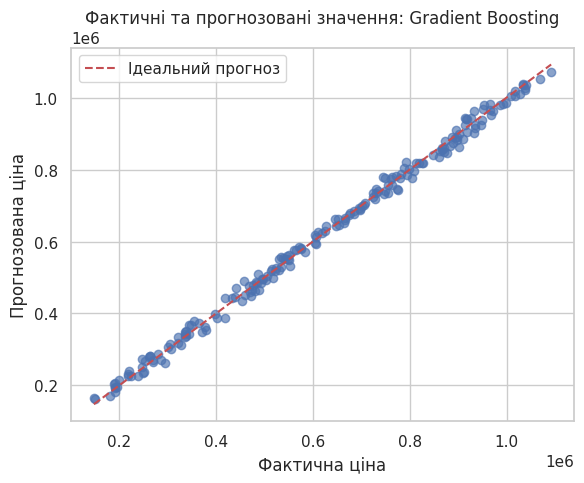

In [ ]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.
for name, y_pred in predictions.items():
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.65)
    low = min(float(np.min(y_test)), float(np.min(y_pred)))
    high = max(float(np.max(y_test)), float(np.max(y_pred)))
    plt.plot([low, high], [low, high], "r--", label="Ідеальний прогноз")
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(f"Фактичні та прогнозовані значення: {name}")
    plt.legend()
    plt.tight_layout()
    plt.show()




## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [ ]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_features": [1.0, "sqrt"],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)
print("Найкращі параметри:")
print(grid_search.best_params_)
print(f"Найкращий середній R² на крос-валідації: {grid_search.best_score_:.4f}")




Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри:
{'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Найкращий середній R² на крос-валідації: 0.9920


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [ ]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.
best_rf = grid_search.best_estimator_
best_rf.fit(X_train, y_train)
best_rf_pred = best_rf.predict(X_test)
optimized_metrics = {
    "Модель": "Random Forest (оптимізований)",
    "R²": r2_score(y_test, best_rf_pred),
    "MAE": mean_absolute_error(y_test, best_rf_pred),
    "MSE": mean_squared_error(y_test, best_rf_pred)
}
display(pd.DataFrame([optimized_metrics]))




,Модель,R²,MAE,MSE
0,Random Forest (оптимізований),0.994,"16,035.168","387,229,091.921"


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [ ]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.
baseline_pred = predictions["Random Forest"]
comparison_rf = pd.DataFrame([
    {
        "Модель": "Random Forest (базовий)",
        "R²": r2_score(y_test, baseline_pred),
        "MAE": mean_absolute_error(y_test, baseline_pred),
        "MSE": mean_squared_error(y_test, baseline_pred)
    },
    optimized_metrics
])
display(comparison_rf)




,Модель,R²,MAE,MSE
0,Random Forest (базовий),0.994,"16,114.290","394,131,747.446"
1,Random Forest (оптимізований),0.994,"16,035.168","387,229,091.921"


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

In [ ]:
base_row = comparison_rf.loc[comparison_rf["Модель"] == "Random Forest (базовий)"].iloc[0]
opt_row = comparison_rf.loc[comparison_rf["Модель"] == "Random Forest (оптимізований)"].iloc[0]
r2_change = opt_row["R²"] - base_row["R²"]
mae_change = opt_row["MAE"] - base_row["MAE"]
mse_change = opt_row["MSE"] - base_row["MSE"]

print("Висновок:")
if r2_change > 0 and mae_change < 0 and mse_change < 0:
    print("Після підбору параметрів усі три метрики покращилися: R² зріс, а MAE та MSE зменшилися.")
elif r2_change > 0:
    print("Після оптимізації R² зріс, однак MAE та/або MSE не обов'язково зменшилися.")
elif abs(r2_change) < 1e-9 and abs(mae_change) < 1e-9 and abs(mse_change) < 1e-9:
    print("Після оптимізації метрики практично не змінилися.")
else:
    print("Після підбору параметрів якість за R² не покращилася; варто порівняти всі метрики та врахувати складність моделі.")
print(f"Зміна R²: {r2_change:+.4f}")
print(f"Зміна MAE: {mae_change:+,.3f} (від'ємне значення — краще)")
print(f"Зміна MSE: {mse_change:+,.3f} (від'ємне значення — краще)")


Висновок:
Після підбору параметрів усі три метрики покращилися: R² зріс, а MAE та MSE зменшилися.
Зміна R²: +0.0001
Зміна MAE: -79.122 (від'ємне значення — краще)
Зміна MSE: -6,902,655.525 (від'ємне значення — краще)


## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [ ]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.

linear_pred = predictions["Linear Regression"]
denominator = np.where(np.abs(np.asarray(y_test)) > 1e-12, np.abs(np.asarray(y_test)), np.nan)
errors_pct = np.abs(np.asarray(y_test) - linear_pred) / denominator * 100

forecast_table = pd.DataFrame({
    "Фактична ціна": np.asarray(y_test),
    "Прогнозована ціна": linear_pred,
    "Похибка у %": errors_pct
}, index=y_test.index)
display(forecast_table.sample(n=min(10, len(forecast_table)), random_state=42).round(2))



,Фактична ціна,Прогнозована ціна,Похибка у %
436,"1,068,538.110","1,059,729.020",0.820
899,"194,353.740","187,868.550",3.340
346,"270,230.640","279,715.820",3.510
60,"986,006.860","981,949.270",0.410
867,"953,339.730","957,382.950",0.420
432,"914,555.750","909,764.270",0.520
543,"746,167.730","742,469.140",0.500
361,"646,766.290","654,445.550",1.190
486,"523,323.070","524,605.440",0.250
277,"1,008,539.160","1,011,343.640",0.280


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

У роботі було побудовано Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting.
Найкращою серед базових моделей за R² стала Linear Regression (R²=0.9984, MAE=8174.584, MSE=101434798.506).
Оптимізований Random Forest: R²=0.9940, MAE=16035.168, MSE=387229091.921.
Точність прогнозів оцінюється за тестовою вибіркою; ближчі до 1 значення R² і менші MAE/MSE означають кращу якість.
На ціну нерухомості можуть впливати площа будинку й ділянки, кількість спалень і ванних кімнат, рік побудови, гараж і якість району. На результат також впливають обсяг та якість даних і ознаки, яких немає в датасеті.

